# 01 · Data Preparation and Exploratory Analysis

**PhilGEPS procurement-failure risk · Notebook 1 of 3**
**Data:** PhilGEPS 1.5 (2023 Q1 – 2026 Q3) and PhilGEPS 2.0 (2026 Q1 – Q3), merged by `scripts/combine_raw.py` into `data/processed/philgeps_combined.parquet`.
**Scope:** Public Bidding (called *Competitive Bidding (Public Bidding)* in PhilGEPS 2.0).

## Business question

Using only information available when a procurement notice is published, **how likely is it that the procurement fails**, ending in a `Failed` bidding instead of an award?

The output is a **procurement-failure risk score per notice**. It supports risk screening and review prioritisation by agencies, oversight bodies and analysts. It is not a model of whether a particular supplier will win, and it does not recommend which bids suppliers should pursue.

## Where this notebook sits

This series re-runs the analytical roadmap of `LT8-ML_Govt_Bidding_Documented.ipynb` on the expanded, merged dataset. LT8 remains the record of the original 14-file run.

| Roadmap step | Notebook |
|---|---|
| 1. Source preparation | **01** (this notebook), Phase 1 |
| 2. Initial EDA | **01**, Phase 2 |
| 3. Data-quality investigation | **01**, Phase 3 |
| 4. Consolidation | **01**, Phase 4 |
| 5. Bid-level modelling table | **01**, Phase 5 → writes `data/processed/bids_public_bidding.parquet` |
| 6. Modelling | `02_modeling.ipynb` |
| 7. Robustness diagnostics | `03_diagnostics_and_interpretation.ipynb` |
| 8. Business interpretation | `03_diagnostics_and_interpretation.ipynb` |
| 9. Findings and limitations | `03_diagnostics_and_interpretation.ipynb` |

## Reviewer questions answered here

- **Q2. Are all features available when the notice is published?** §5.6 classifies every field by when it becomes known.
- **Q3. How are ongoing, cancelled and closed bids handled?** §5.2 defines the outcome rule and shows the handling of every status.
- **Q4. How many observations, and what is the awarded/failed split?** §5.7.

## How to run

From the repository root: `git lfs pull`, then `python scripts/combine_raw.py`. Then run this notebook top to bottom. It reads the combined Parquet file, plus the raw CSVs for the source checks in Phase 1 and Phase 3. Peak memory is about 3 GB.

In [1]:
import hashlib
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display

import procurement_failure as pf

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 80)

print("Repository root:", pf.ROOT)
print("Combined dataset:", pf.COMBINED, "| exists:", pf.COMBINED.exists())
if not pf.COMBINED.exists():
    raise FileNotFoundError("Run `python scripts/combine_raw.py` from the repository root first.")

Repository root: C:\Users\Deborah Argayosa\Documents\GitHub\philgeps-ml-project
Combined dataset: C:\Users\Deborah Argayosa\Documents\GitHub\philgeps-ml-project\data\processed\philgeps_combined.parquet | exists: True


## Phase 1. Source preparation

### 1.1 Raw file inventory

`data/raw/` holds 30 quarterly CSVs. The file name gives the system and quarter: `<system>_<year>_Q<quarter>.csv`. The `2.0_2023_*` to `2.0_2025_*` files were found to be byte-for-byte copies of the matching `1.5_*` files. PhilGEPS 2.0 only went live in 2026, so these "2.0" files are 1.5 exports saved under a 2.0 name. The cell verifies this with an MD5 checksum of every pair. The combine script skips those 12 files so 2023–2025 is not double-counted.

In [2]:
def md5(path, block=1 << 24):
    h = hashlib.md5()
    with open(path, "rb") as f:
        while chunk := f.read(block):
            h.update(chunk)
    return h.hexdigest()

rows = []
for f in sorted(pf.RAW.glob("*.csv")):
    system, year, quarter = f.stem.split("_")
    rows.append({"File": f.name, "System": system, "Year": int(year), "Quarter": quarter,
                 "Size (MB)": round(f.stat().st_size / 1e6, 1)})
inventory = pd.DataFrame(rows)

# Verify the duplicate claim with full checksums.
dup_check = []
for f in inventory.loc[(inventory.System == "2.0") & (inventory.Year < 2026), "File"]:
    twin = "1.5" + f[3:]
    same = md5(pf.RAW / f) == md5(pf.RAW / twin)
    dup_check.append({"2.0 file": f, "1.5 file": twin, "Identical (MD5)": same})
dup_check = pd.DataFrame(dup_check)
display(dup_check)

dups = set(dup_check.loc[dup_check["Identical (MD5)"], "2.0 file"])
inventory["Used"] = np.where(inventory.File.isin(dups), "skipped: duplicate of 1.5 file", "used")
display(inventory)
print(f"Files used: {(inventory.Used == 'used').sum()} | skipped duplicates: {len(dups)}")

,2.0 file,1.5 file,Identical (MD5)
0,2.0_2023_Q1.csv,1.5_2023_Q1.csv,True
1,2.0_2023_Q2.csv,1.5_2023_Q2.csv,True
2,2.0_2023_Q3.csv,1.5_2023_Q3.csv,True
3,2.0_2023_Q4.csv,1.5_2023_Q4.csv,True
4,2.0_2024_Q1.csv,1.5_2024_Q1.csv,True
5,2.0_2024_Q2.csv,1.5_2024_Q2.csv,True
6,2.0_2024_Q3.csv,1.5_2024_Q3.csv,True
7,2.0_2024_Q4.csv,1.5_2024_Q4.csv,True
8,2.0_2025_Q1.csv,1.5_2025_Q1.csv,True
9,2.0_2025_Q2.csv,1.5_2025_Q2.csv,True


,File,System,Year,Quarter,Size (MB),Used
0,1.5_2023_Q1.csv,1.5,2023,Q1,292.2,used
1,1.5_2023_Q2.csv,1.5,2023,Q2,310.2,used
2,1.5_2023_Q3.csv,1.5,2023,Q3,323.7,used
3,1.5_2023_Q4.csv,1.5,2023,Q4,328.0,used
4,1.5_2024_Q1.csv,1.5,2024,Q1,321.2,used
5,1.5_2024_Q2.csv,1.5,2024,Q2,345.4,used
6,1.5_2024_Q3.csv,1.5,2024,Q3,340.5,used
7,1.5_2024_Q4.csv,1.5,2024,Q4,373.1,used
8,1.5_2025_Q1.csv,1.5,2025,Q1,337.1,used
9,1.5_2025_Q2.csv,1.5,2025,Q2,263.9,used


Files used: 18 | skipped duplicates: 12


### 1.2 Raw layouts

The used files come in four formats. The combine script maps them all onto the 1.5 (2023–2025) column names. The check below reads the first line and the first 20 MB of each file to report its delimiter, encoding and column count.

In [3]:
def describe_raw(path):
    head = open(path, "rb").read(20_000_000)
    bom = head.startswith(b"\xef\xbb\xbf")
    try:
        head.decode("utf-8")
        encoding = "UTF-8" + (" with BOM" if bom else "")
    except UnicodeDecodeError as e:
        # A cut multi-byte character at the 20 MB boundary is still UTF-8.
        encoding = "UTF-8" if e.start > len(head) - 4 else "Windows-1252"
    first = head.split(b"\n", 1)[0]
    delim = "tab" if first.count(b"\t") > first.count(b",") else "comma"
    header = pd.read_csv(path, nrows=0, sep="\t" if delim == "tab" else ",",
                         encoding="utf-8-sig" if encoding.startswith("UTF") else "cp1252").columns
    return delim, encoding, len(header), "Solicitation No." in header, "Lot Type" in header

layout_rows = []
for f in inventory.loc[inventory.Used == "used", "File"]:
    delim, enc, ncol, has_solicitation, has_lot = describe_raw(pf.RAW / f)
    layout = ("2.0 (2026)" if has_lot else "1.5 (2026 layout)" if has_solicitation
              else "1.5 2025 Q4 (tab, shifted)" if delim == "tab" else "1.5 (2023–2025 layout)")
    layout_rows.append({"File": f, "Layout": layout, "Delimiter": delim, "Encoding": enc, "Columns": ncol})
layouts = pd.DataFrame(layout_rows)
display(layouts)
display(layouts.groupby(["Layout", "Delimiter", "Encoding", "Columns"]).size().rename("Files").reset_index())

,File,Layout,Delimiter,Encoding,Columns
0,1.5_2023_Q1.csv,1.5 (2023–2025 layout),comma,UTF-8 with BOM,46
1,1.5_2023_Q2.csv,1.5 (2023–2025 layout),comma,UTF-8 with BOM,46
2,1.5_2023_Q3.csv,1.5 (2023–2025 layout),comma,UTF-8 with BOM,46
3,1.5_2023_Q4.csv,1.5 (2023–2025 layout),comma,UTF-8 with BOM,46
4,1.5_2024_Q1.csv,1.5 (2023–2025 layout),comma,UTF-8 with BOM,46
5,1.5_2024_Q2.csv,1.5 (2023–2025 layout),comma,UTF-8 with BOM,46
6,1.5_2024_Q3.csv,1.5 (2023–2025 layout),comma,UTF-8 with BOM,46
7,1.5_2024_Q4.csv,1.5 (2023–2025 layout),comma,UTF-8 with BOM,46
8,1.5_2025_Q1.csv,1.5 (2023–2025 layout),comma,UTF-8 with BOM,46
9,1.5_2025_Q2.csv,1.5 (2023–2025 layout),comma,UTF-8 with BOM,46


,Layout,Delimiter,Encoding,Columns,Files
0,1.5 (2023–2025 layout),comma,UTF-8 with BOM,46,11
1,1.5 (2026 layout),comma,Windows-1252,47,3
2,"1.5 2025 Q4 (tab, shifted)",tab,Windows-1252,46,1
3,2.0 (2026),comma,UTF-8,45,3


### 1.3 The combined dataset

`scripts/combine_raw.py` produces one row per bid line item, with three lineage columns: `Source System`, `Source File` and `Source Quarter`. The raw files are not modified.

In [4]:
pfile = pq.ParquetFile(pf.COMBINED)
print(f"Rows: {pfile.metadata.num_rows:,} | Columns: {len(pfile.schema_arrow.names)} | "
      f"Size: {pf.COMBINED.stat().st_size / 1e6:.0f} MB")

lineage = pq.read_table(pf.COMBINED, columns=["Source System", "Source File"]).to_pandas()
per_file = lineage.groupby(["Source System", "Source File"], observed=True).size().rename("Line items").reset_index()
display(per_file)
print("Line items by system:", lineage["Source System"].value_counts().to_dict())
del lineage

print("\nColumns:")
print(", ".join(pfile.schema_arrow.names))

Rows: 6,059,201 | Columns: 54 | Size: 422 MB


,Source System,Source File,Line items
0,1.5,1.5_2023_Q1.csv,405796
1,1.5,1.5_2023_Q2.csv,436736
2,1.5,1.5_2023_Q3.csv,450701
3,1.5,1.5_2023_Q4.csv,450311
4,1.5,1.5_2024_Q1.csv,440342
5,1.5,1.5_2024_Q2.csv,474381
6,1.5,1.5_2024_Q3.csv,469108
7,1.5,1.5_2024_Q4.csv,512719
8,1.5,1.5_2025_Q1.csv,469569
9,1.5,1.5_2025_Q2.csv,372122


Line items by system: {'1.5': 5911134, '2.0': 148067}

Columns:
Source System, Source File, Source Quarter, Procuring Entity (PE), Region, Province, City/Municipality, Government Branch, PE Organization Type, PE Organization Type (Grouped), Bid Reference No., Solicitation No., Notice Title, Classification, Procurement Mode, Procurement Mode (Grouped), Business Category, Funding Source, Funding Instrument, Trade Agreement, Approved Budget of the Contract, Published Date, Closing Date, Area of Delivery, Contract Duration, Calendar Type, Lot Type, Line Item No, Item Code, Item Name, Item Description, Quantity, UOM, Item Budget, Bid Notice Status, Award Reference No., Award Title, UNSPSC Code, UNSPSC Description, Published Date(Award), Award Date, Contract Amount, Award Notice Status, Notice to Proceed Date, Contract Effectivity Date, Contract End Date, Awardee OrgID, Awardee Organization Name, Country of Awardee, Region of Awardee, Province of Awardee, City/Municipality of Awardee, Awarde

## Phase 2. Initial exploratory analysis

### 2.1 Procurement modes and the choice of Public Bidding

Procurement mode labels changed between the systems. For example, `Negotiated Procurement - Small Value Procurement (Sec. 53.9)` in 1.5 corresponds to `Small Value Procurement` in 2.0, and `Public Bidding` corresponds to `Competitive Bidding (Public Bidding)`. The combine script adds `Procurement Mode (Grouped)`, which strips section numbers and maps the 2.0 names onto the 1.5 names.

Public Bidding is the modelling scope. It is the main competitive mode, and a *failed bidding* is a formally defined outcome only in competitive bidding. Small-value procurement and shopping are high-volume but follow different rules.

Source System,1.5,2.0,Total bids,Share (%)
Procurement Mode (Grouped),,,,
Small Value Procurement,1884128,36219,1920347,53.04
Public Bidding,1251464,26008,1277472,35.28
Shopping - Ordinary/Regular Office Supplies & Equipment,359356,276,359632,9.93
Negotiated Procurement - Two Failed Biddings,56887,331,57218,1.58
Negotiated Procurement - NGO Participation,3391,3,3394,0.09
International Competitive Bidding,1521,19,1540,0.04
Negotiated Procurement - Lease of Real Property and Venue,1,443,444,0.01
Limited Source Bidding,152,21,173,0.00
Negotiated Procurement - Community Participation,1,104,105,0.00


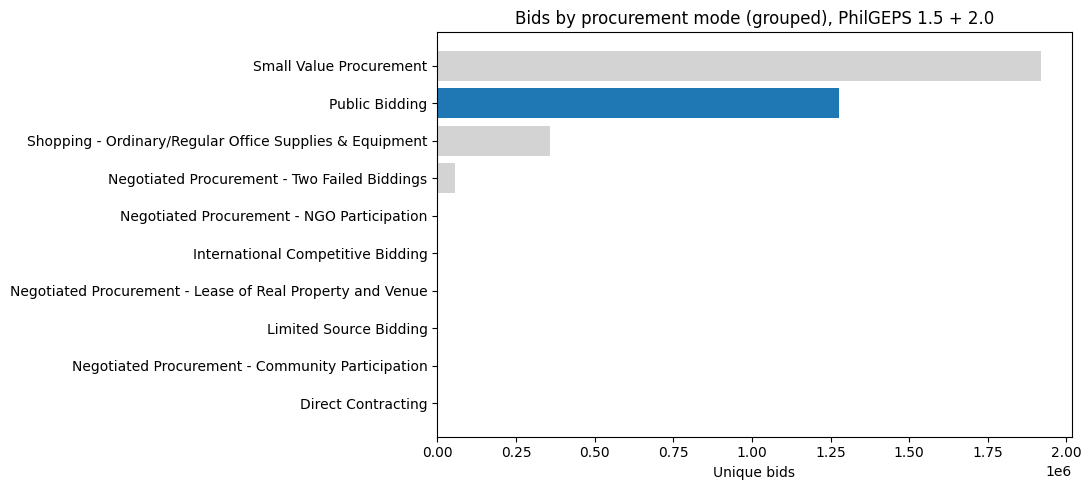

In [5]:
modes = pq.read_table(pf.COMBINED, columns=["Source System", "Procurement Mode (Grouped)", "Bid Reference No."]).to_pandas()
mode_bids = (modes.drop_duplicates(["Source System", "Bid Reference No.", "Procurement Mode (Grouped)"])
             .groupby(["Procurement Mode (Grouped)", "Source System"], observed=True).size().unstack(fill_value=0))
mode_bids["Total bids"] = mode_bids.sum(axis=1)
mode_bids = mode_bids.sort_values("Total bids", ascending=False)
mode_bids["Share (%)"] = (mode_bids["Total bids"] / mode_bids["Total bids"].sum() * 100).round(2)
display(mode_bids.head(15))
del modes

top = mode_bids.head(10)["Total bids"].sort_values()
plt.figure(figsize=(11, 5))
plt.barh(top.index, top.values, color=["tab:blue" if i == "Public Bidding" else "lightgray" for i in top.index])
plt.xlabel("Unique bids")
plt.title("Bids by procurement mode (grouped), PhilGEPS 1.5 + 2.0")
plt.tight_layout(); plt.show()

### 2.2 Load Public Bidding line items

From here on, only Public Bidding line items are used. The filter is applied while reading the Parquet file, so only those rows are loaded.

In [6]:
items = pf.load_public_bidding_items(pf.ITEM_COLUMNS + ["Award Notice Status", "Procurement Mode"])
print(f"Public Bidding line items: {len(items):,}")
print(f"Unique bids: {items.groupby(pf.KEY, observed=True).ngroups:,}")
print("\nRaw procurement-mode labels mapped to Public Bidding:")
display(items.groupby(["Source System", "Procurement Mode"], observed=True).size().rename("Line items").reset_index())

Public Bidding line items: 2,145,310


Unique bids: 1,277,472

Raw procurement-mode labels mapped to Public Bidding:


,Source System,Procurement Mode,Line items
0,1.5,Public Bidding,2089077
1,2.0,Competitive Bidding (Public Bidding),56233


### 2.3 Outcome statuses

`Bid Notice Status` is the outcome of the notice: `Awarded`, `Failed`, `Closed`, `Cancelled`, `Active` and `Shortlisted` in 1.5. PhilGEPS 2.0 uses `Published`, `CANCEL_APPROVED` and `CONCLUDED`, which the combine script maps to `Active`, `Cancelled` and `Concluded`.

`Award Notice Status` describes the award notice, not the bidding outcome, and its vocabulary differs between systems: `Posted`/`Updated` in 1.5, `Published`/`NTP Issued` in 2.0. The cross-tab shows how the two fields relate. Some `Closed` notices already carry an award notice. This is why the outcome is taken from `Bid Notice Status` alone and only the explicit `Awarded`/`Failed` values are used.

In [7]:
for system in ["1.5", "2.0"]:
    sub = items[items["Source System"] == system]
    ct = pd.crosstab(sub["Bid Notice Status"].astype("string").fillna("(missing)"),
                     sub["Award Notice Status"].astype("string").fillna("(no award notice)"))
    print(f"PhilGEPS {system}: Bid Notice Status (rows) x Award Notice Status (columns), line items")
    display(ct)

PhilGEPS 1.5: Bid Notice Status (rows) x Award Notice Status (columns), line items


Award Notice Status,(no award notice),Cancelled,Posted,Updated
Bid Notice Status,,,,
Active,31948,0,0,0
Awarded,87310,3828,85385,697516
Cancelled,74287,0,0,0
Closed,895693,424,23668,106996
Failed,81171,0,0,1
Shortlisted,849,0,0,1


PhilGEPS 2.0: Bid Notice Status (rows) x Award Notice Status (columns), line items


Award Notice Status,(no award notice),Cancelled,DRAFT_APR,NTP Issued,Published
Bid Notice Status,,,,,
Active,11118,0,0,0,0
Awarded,4727,37,19,3519,4841
Cancelled,51,0,0,5,3
Closed,22535,3,15,713,626
Concluded,109,0,0,0,0
Failed,7871,13,0,12,16


### 2.4 Unit of observation

One bid (`Bid Reference No.`) can have many line items. If line items were modelled as separate observations, large multi-item procurements would carry much more weight, and near-identical rows from the same bid could land in both the training and the test set. The modelling unit is therefore **one bid**. Bid references are numbered independently in each system: 1.5 uses 7–8 digit numbers, 2.0 uses short ones. So the key is (`Source System`, `Bid Reference No.`).

This cell also counts exact duplicate line items (identical in every column). It hashes each row while streaming the file in batches.

In [8]:
per_bid = items.groupby(pf.KEY, observed=True).size()
print("Line items per bid:")
display(per_bid.describe(percentiles=[.5, .75, .9, .99]).round(1).to_frame("line items").T)
print(f"Bids with a single line item: {(per_bid == 1).mean() * 100:.1f}%")
print("Most repeated bids:")
display(per_bid.sort_values(ascending=False).head(5).rename("line items").reset_index())

# Exact duplicate line items across all 55 columns.
hashes = []
reader = pq.ParquetFile(pf.COMBINED)
for batch in reader.iter_batches(batch_size=200_000):
    frame = batch.to_pandas()
    frame = frame[frame["Procurement Mode (Grouped)"] == "Public Bidding"].drop(columns=["Source File", "Source Quarter"])
    hashes.append(pd.util.hash_pandas_object(frame, index=False).to_numpy())
hashes = np.concatenate(hashes)
n_dup = len(hashes) - len(np.unique(hashes))
print(f"\nExact duplicate Public Bidding line items: {n_dup:,} of {len(hashes):,} ({n_dup / len(hashes) * 100:.2f}%)")
print("Duplicates do not affect the bid-level table, which aggregates per bid.")
del hashes

Line items per bid:


,count,mean,std,min,50%,75%,90%,99%,max
line items,1277472.0,1.7,11.5,1.0,1.0,1.0,1.0,13.0,3969.0


Bids with a single line item: 91.9%
Most repeated bids:


,Source System,Bid Reference No.,line items
0,1.5,9571307,3969
1,1.5,9899898,3350
2,1.5,10390358,3136
3,1.5,10522142,2820
4,1.5,11428638,1794



Exact duplicate Public Bidding line items: 306,535 of 2,145,310 (14.29%)
Duplicates do not affect the bid-level table, which aggregates per bid.


## Phase 3. Data-quality investigation

### 3.1 The 2025 Q4 column shift

`1.5_2025_Q4.csv` has 46 fields like the other 1.5 files, but the `Calendar Type` value is missing and every later value sits one column to the left. Read naively, `Bid Notice Status` holds award reference numbers and the statuses appear under `Item Budget`. A header count cannot catch this; the check has to look at the values. The combine script reassigns the column names one position to the right and stops if the trailing column holds any data. This cell confirms the problem in the raw file and the repair in the combined file.

In [9]:
raw_q4 = pd.read_csv(pf.RAW / "1.5_2025_Q4.csv", sep="\t", encoding="cp1252", encoding_errors="replace",
                     dtype=str, na_values=["NULL"], nrows=200_000)
print("Raw file read naively (first 200,000 rows):")
print("  'Bid Notice Status' column, top values:", raw_q4["Bid Notice Status"].value_counts(dropna=False).head(4).to_dict())
print("  'Item Budget' column, top values:      ", raw_q4["Item Budget"].value_counts(dropna=False).head(6).to_dict())
print("  last column all empty:", raw_q4.iloc[:, -1].isna().all())
del raw_q4

q4 = pq.read_table(pf.COMBINED, columns=["Bid Notice Status", "Item Budget", "Contract Duration", "Calendar Type"],
                   filters=[("Source File", "=", "1.5_2025_Q4.csv")]).to_pandas()
print("\nCombined file after repair (all 1.5_2025_Q4 rows):")
print("  Bid Notice Status:", q4["Bid Notice Status"].value_counts(dropna=False).to_dict())
print("  Item Budget numeric share:", round(q4["Item Budget"].notna().mean(), 4))
print("  Calendar Type:", q4["Calendar Type"].value_counts(dropna=False).to_dict())
del q4

Raw file read naively (first 200,000 rows):
  'Bid Notice Status' column, top values: {nan: 198721, '5882412': 150, '5909965': 64, '5857006': 60}
  'Item Budget' column, top values:       {'Closed': 144281, 'Awarded': 45669, 'Cancelled': 5777, 'Failed': 4006, 'Active': 246, 'Shortlisted': 21}
  last column all empty: True

Combined file after repair (all 1.5_2025_Q4 rows):
  Bid Notice Status: {'Closed': 269298, 'Awarded': 61111, 'Cancelled': 9815, 'Failed': 6048, 'Active': 5773, 'Shortlisted': 46}
  Item Budget numeric share: 0.5666
  Calendar Type: {'Day/s': 340589, nan: 5690, 'Month/s': 3508, 'Year/s': 2304}


### 3.2 Harmonised labels

These labels differ between the systems only in spelling or naming, and are harmonised in the combined file:

- **Bid Notice Status (2.0):** `Published` → `Active`, `CANCEL_APPROVED` → `Cancelled`, `CONCLUDED` → `Concluded`.
- **Classification (2.0):** `Civil Works - Infra Project` → `Civil Works`.
- **Region (2.0):** upper-case variants such as `REGION IX` → `Region IX`, and `ARMM` → `BARMM`.
- **Procurement mode:** grouped as described in §2.1.
- **Contract duration:** `30 Day/s` and `1 years` are split into a number and a unit.

The raw 2.0 values are read directly from the 2.0 CSVs below, to show what the mapping changed.

In [10]:
raw20 = pd.concat([pd.read_csv(pf.RAW / f"2.0_2026_Q{q}.csv", dtype=str, na_values=["NULL"],
                               usecols=["Bid Notice Status", "Classification", "Region"]) for q in (1, 2, 3)])
for col in ["Bid Notice Status", "Classification"]:
    print(f"Raw PhilGEPS 2.0 '{col}':", raw20[col].value_counts(dropna=False).to_dict())
regions_15 = set(items.loc[items["Source System"] == "1.5", "Region"].dropna().astype(str))
raw_regions = raw20["Region"].dropna()
odd = raw_regions[~raw_regions.isin(regions_15)].value_counts()
print("Raw 2.0 Region values not spelled as in 1.5 (line items):", odd.to_dict())
print("Region values in the combined 2.0 rows that are still not in the 1.5 list:",
      sorted(set(items.loc[items["Source System"] == "2.0", "Region"].dropna().astype(str)) - regions_15))
del raw20

Raw PhilGEPS 2.0 'Bid Notice Status': {'Closed': 78984, 'Awarded': 35370, 'Published': 16819, 'Failed': 16429, 'CONCLUDED': 338, 'CANCEL_APPROVED': 127}
Raw PhilGEPS 2.0 'Classification': {'Goods': 123744, 'Civil Works - Infra Project': 15512, 'Goods - General Support Services': 7851, 'Consulting Services': 960}


Raw 2.0 Region values not spelled as in 1.5 (line items): {'CARAGA': 212, 'ARMM': 101, 'REGION VI': 43, 'REGION IV-A': 42, 'REGION II': 31, 'REGION V': 27, 'REGION X': 19, 'REGION I': 17, 'NEGROS ISLAND REGION': 14, 'REGION XI': 14, 'REGION VII': 9, 'REGION IX': 9, 'REGION XII': 9, 'REGION IV-B': 6, 'REGION VIII': 2, 'Cotabato': 2}
Region values in the combined 2.0 rows that are still not in the 1.5 list: []


### 3.3 Vocabularies that are not comparable between systems

`Business Category` and `Funding Source` mean the same thing in both systems, but use different value sets. PhilGEPS 2.0 categories are product-family names (`Office supplies`, `Heavy construction services`). 2.0 funding sources are budget fund codes (`Regular Agency Fund (01000000)`) rather than lenders (`Government of the Philippines (GOP)`). These values are kept as they are, not forced into a mapping. The models therefore see `Source System` as a feature, and the diagnostics in notebook 03 report results separately for each system.

In [11]:
for col in ["Business Category", "Funding Source", "Trade Agreement"]:
    v15 = set(items.loc[items["Source System"] == "1.5", col].dropna().astype(str))
    v20 = set(items.loc[items["Source System"] == "2.0", col].dropna().astype(str))
    print(f"{col}: {len(v15)} values in 1.5, {len(v20)} in 2.0, {len(v15 & v20)} shared")
print("\nTop 2.0 funding sources:", items.loc[items["Source System"] == "2.0", "Funding Source"].value_counts().head(4).to_dict())

Business Category: 168 values in 1.5, 339 in 2.0, 3 shared


Funding Source: 5 values in 1.5, 9 in 2.0, 0 shared


Trade Agreement: 7 values in 1.5, 5 in 2.0, 5 shared

Top 2.0 funding sources: {'Regular Agency Fund (01000000)': 47655, 'Internally Generated Funds (05000000)': 4792, 'Trust Receipts (07000000)': 1530, 'Special Account - Locally Funded/Domestic Grants Fund (03000000)': 1135}


### 3.4 Date and amount parsing

The combine script reports values it could not parse; it reported none. This check confirms that each line item's publication date falls in the quarter of the file it came from. Small deviations are expected: notices published just before a quarter starts can appear in that quarter's file.

In [12]:
pub_q = items["Published Date"].dt.year.astype("Int64").astype(str) + "Q" + items["Published Date"].dt.quarter.astype("Int64").astype(str)
match = (pub_q == items["Source Quarter"].astype(str))
print(f"Missing published dates: {items['Published Date'].isna().sum():,}")
print(f"Line items whose published date is in the file's quarter: {match.mean() * 100:.2f}%")
mismatch = items.loc[~match].groupby(["Source Quarter"], observed=True).size().rename("Line items outside quarter")
display(mismatch[mismatch > 0].to_frame())

Missing published dates: 0
Line items whose published date is in the file's quarter: 100.00%


,Line items outside quarter
Source Quarter,


## Phase 4. Consolidation

Public Bidding line items and unique bids by quarter and system. In 2026 both systems ran side by side with **separate notices**: no bid reference appears in both. The 1.5 exports carry most of the 2026 volume.

,line_items (1.5),line_items (2.0),bids (1.5),bids (2.0)
Source Quarter,,,,
2023Q1,147699,0,80302,0
2023Q2,156417,0,94232,0
2023Q3,157757,0,88703,0
2023Q4,166433,0,81570,0
2024Q1,154137,0,80384,0
2024Q2,166433,0,91787,0
2024Q3,169905,0,94438,0
2024Q4,203345,0,111427,0
2025Q1,163122,0,99652,0


Total: 2,145,310 line items, 1,277,472 bids


Bid references present in both systems: 0


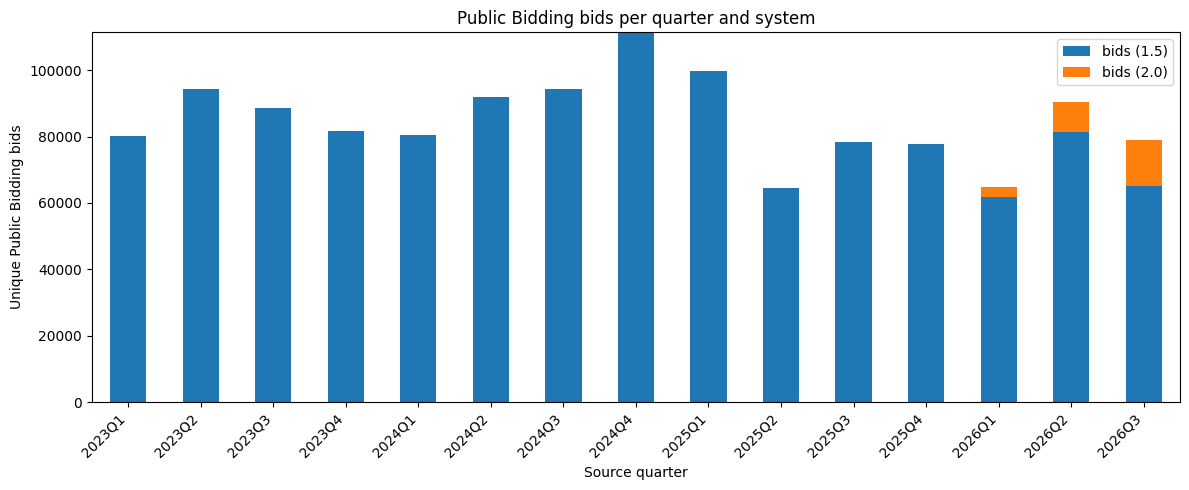

In [13]:
consol = items.groupby(["Source Quarter", "Source System"], observed=True).agg(
    line_items=("Bid Notice Status", "size"),
    bids=("Bid Reference No.", "nunique"),
).unstack("Source System", fill_value=0)
consol.columns = [f"{a} ({b})" for a, b in consol.columns]
display(consol)
print(f"Total: {len(items):,} line items, {items.groupby(pf.KEY, observed=True).ngroups:,} bids")

shared = set(items.loc[items["Source System"] == "1.5", "Bid Reference No."]) & set(items.loc[items["Source System"] == "2.0", "Bid Reference No."])
print(f"Bid references present in both systems: {len(shared)}")

ax = consol[[c for c in consol.columns if c.startswith("bids")]].plot(kind="bar", stacked=True, figsize=(12, 5))
ax.set_ylabel("Unique Public Bidding bids"); ax.set_xlabel("Source quarter")
ax.set_title("Public Bidding bids per quarter and system")
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

## Phase 5. Bid-level modelling table

### 5.1 Build one row per bid

`pf.build_bid_table` aggregates line items to one row per bid. It:

1. Assigns one status per bid. A bid takes a status only when **all** its line items have that status; otherwise it is `Conflicting`.
2. Takes the approved budget, publication date, closing date, contract duration and category fields per bid, and counts how many distinct values each field has within the bid (the *version count*).
3. **Excludes** bids that cannot be described consistently: missing or non-positive approved budget, more than one approved budget, more than one publication date, or more than one `Business Category`, `Region` or `Classification`. These go to an exceptions log with the reason.
4. Where a bid has several funding sources or funding instruments (mostly multi-lot bids), uses the most frequent one and sets the flag `multi_funding_source`, rather than dropping the bid.
5. Sets impossible bidding windows (negative or over a year) and contract durations over ten years to missing, rather than dropping the bid.

In [14]:
bids, exceptions = pf.build_bid_table(items)
print(f"Bids in the modelling table: {len(bids):,}")
print(f"Bids excluded for data quality: {len(exceptions):,}")
display(exceptions["reason"].value_counts().rename("Bids").to_frame())
print("Excluded bids by status:", exceptions["status"].value_counts().to_dict())
exceptions.to_csv(pf.EXCEPTIONS, index=False)
print("Exceptions log written to", pf.EXCEPTIONS.relative_to(pf.ROOT))

Bids in the modelling table: 1,277,213
Bids excluded for data quality: 259


,Bids
reason,
non-positive approved budget,252
more than one approved budget; more than one published date; more than one Business Category; more than one Region; more than one Classification,2
more than one approved budget; more than one published date,1
more than one approved budget; more than one published date; more than one Business Category,1
more than one approved budget; more than one Business Category; more than one Region,1
more than one approved budget; more than one published date; more than one Business Category; more than one Classification,1
more than one approved budget; more than one Business Category; more than one Region; more than one Classification,1


Excluded bids by status: {'Closed': 148, 'Awarded': 48, 'Cancelled': 41, 'Failed': 13, 'Active': 7, 'Conflicting': 2}
Exceptions log written to data\processed\bids_public_bidding_exceptions.csv


### 5.2 Outcome definition and handling of every status (reviewer Q3)

| Bid status | Meaning | Handling in the main target `Target_Failed` | Sensitivity target `Target_Failed_or_Cancelled` |
|---|---|---|---|
| `Awarded` | contract awarded | **0** | 0 |
| `Failed` | failed bidding declared | **1** | 1 |
| `Closed` | submission deadline passed, no outcome posted | unlabelled, excluded | unlabelled |
| `Cancelled` | notice withdrawn by the agency | unlabelled, excluded | **1** |
| `Active` / 2.0 `Published` | still open | unlabelled, excluded | unlabelled |
| `Shortlisted` | in evaluation | unlabelled, excluded | unlabelled |
| `Concluded` (2.0 only) | process ended, outcome not stated | unlabelled, excluded | unlabelled |
| `Conflicting` | line items disagree | unlabelled, excluded | unlabelled |

Ongoing, closed and cancelled notices are **not** treated as failures. Cancellation is a different event from a failed bidding: the agency withdraws the notice, rather than the bidding producing no acceptable bid. Notebook 02 tests how much the results change if cancellations are counted as failures.

In [15]:
def status_table(frame):
    t = pd.crosstab(frame["status"], frame["Source System"], margins=True, margins_name="All")
    t = t.reindex([s for s in pf.STATUS_ORDER if s in t.index] + ["All"])
    t["Share (%)"] = (t["All"] / len(frame) * 100).round(2)
    t["Target_Failed"] = t.index.map({"Awarded": "0", "Failed": "1"}).fillna("excluded")
    t.loc["All", "Target_Failed"] = ""
    return t

display(status_table(bids))

Source System,1.5,2.0,All,Share (%),Target_Failed
status,,,,,
Awarded,497093,7257,504350,39.49,0
Failed,64509,4726,69235,5.42,1
Closed,607495,9915,617410,48.34,excluded
Cancelled,60169,13,60182,4.71,excluded
Active,21213,4079,25292,1.98,excluded
Shortlisted,731,0,731,0.06,excluded
Concluded,0,13,13,0.00,excluded
All,1251210,26003,1277213,100.00,


### 5.3 Label coverage and failure rate by quarter

*Label coverage* is the share of bids with a final `Awarded` or `Failed` status. It drops sharply for recent quarters, because many notices are still `Closed` or `Active`. The failure rate among labelled bids is therefore conditional on an outcome having been posted. It is not the failure rate of all published notices, and recent quarters are the most affected.

,,bids,labelled,failed,Label coverage (%),Failure rate among labelled (%)
source_quarter,Source System,,,,,
2023Q1,1.5,80290,42986,5013.0,53.5,11.66
2023Q2,1.5,94225,46013,5799.0,48.8,12.60
2023Q3,1.5,88688,44433,5415.0,50.1,12.19
2023Q4,1.5,81544,50514,5882.0,61.9,11.64
2024Q1,1.5,80367,46767,4815.0,58.2,10.30
2024Q2,1.5,91765,49246,5492.0,53.7,11.15
2024Q3,1.5,94429,47645,5481.0,50.5,11.50
2024Q4,1.5,111379,59967,6473.0,53.8,10.79
2025Q1,1.5,99630,50306,4254.0,50.5,8.46


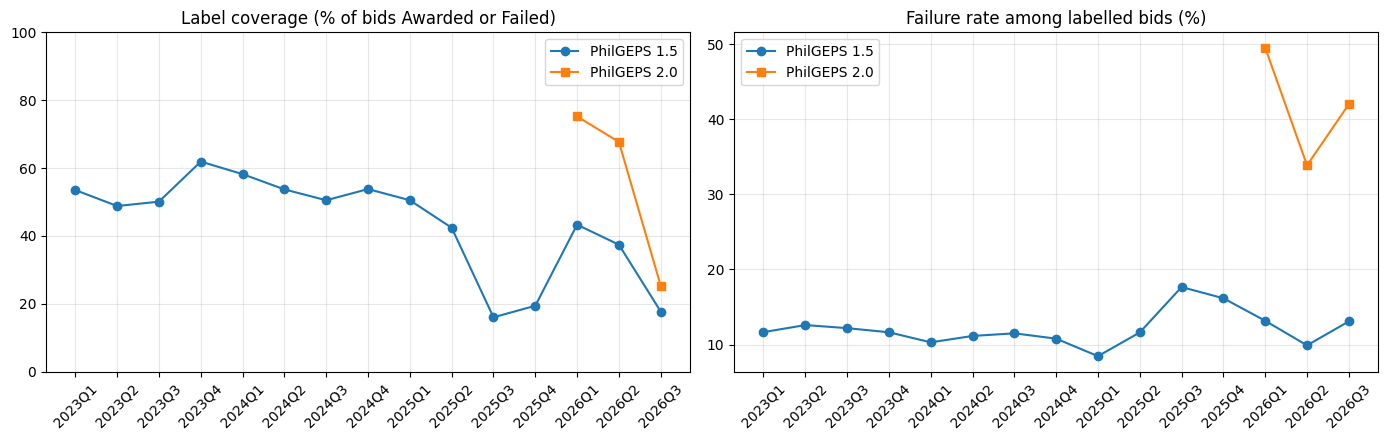

In [16]:
cov = bids.groupby(["source_quarter", "Source System"], observed=True).agg(
    bids=("status", "size"),
    labelled=("Target_Failed", "count"),
    failed=("Target_Failed", "sum"),
)
cov["Label coverage (%)"] = (cov["labelled"] / cov["bids"] * 100).round(1)
cov["Failure rate among labelled (%)"] = (cov["failed"] / cov["labelled"] * 100).round(2)
display(cov)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for system, style in [("1.5", "-o"), ("2.0", "-s")]:
    sub = cov.xs(system, level="Source System")
    axes[0].plot(sub.index.astype(str), sub["Label coverage (%)"], style, label=f"PhilGEPS {system}")
    axes[1].plot(sub.index.astype(str), sub["Failure rate among labelled (%)"], style, label=f"PhilGEPS {system}")
axes[0].set_title("Label coverage (% of bids Awarded or Failed)"); axes[0].set_ylim(0, 100)
axes[1].set_title("Failure rate among labelled bids (%)")
for ax in axes:
    ax.tick_params(axis="x", rotation=45); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

### 5.4 Feature completeness and consistency

For each candidate feature, the table shows the share of missing values and the share of bids where line items disagreed (version count above one). High completeness does not guarantee that a field means the same thing across systems; see §3.3.

In [17]:
feature_cols = pf.EXPANDED_NUMERIC + [c for c in pf.EXPANDED_CATEGORICAL if c not in ("Source System",)]
audit = pd.DataFrame({
    "Missing (%)": bids[feature_cols].isna().mean().mul(100).round(2),
    "Distinct values": bids[feature_cols].nunique(),
})
audit["Missing in 1.5 (%)"] = bids.loc[bids["Source System"] == "1.5", feature_cols].isna().mean().mul(100).round(2)
audit["Missing in 2.0 (%)"] = bids.loc[bids["Source System"] == "2.0", feature_cols].isna().mean().mul(100).round(2)
display(audit)
print("Bids flagged with more than one funding source:", int(bids["multi_funding_source"].sum()))

,Missing (%),Distinct values,Missing in 1.5 (%),Missing in 2.0 (%)
log_approved_budget,0.00,472621,0.00,0.00
bidding_window_days,0.00,239,0.00,0.02
log_n_line_items,0.00,455,0.00,0.00
log_contract_duration_days,0.01,828,0.01,0.06
multi_funding_source,0.00,2,0.00,0.00
Funding Source,0.00,14,0.00,0.00
Business Category,0.00,504,0.00,0.00
Region,0.00,18,0.00,0.00
published_month,0.00,12,0.00,0.00
Classification,0.00,4,0.00,0.00


Bids flagged with more than one funding source: 368


### 5.5 Budget and bidding-window validation

The approved budget is positive for every retained bid; non-positive budgets were excluded in §5.1. It spans several orders of magnitude, so models use `log(1 + budget)`. The bidding window is the number of days from publication to the closing date. Both are known when the notice is posted.

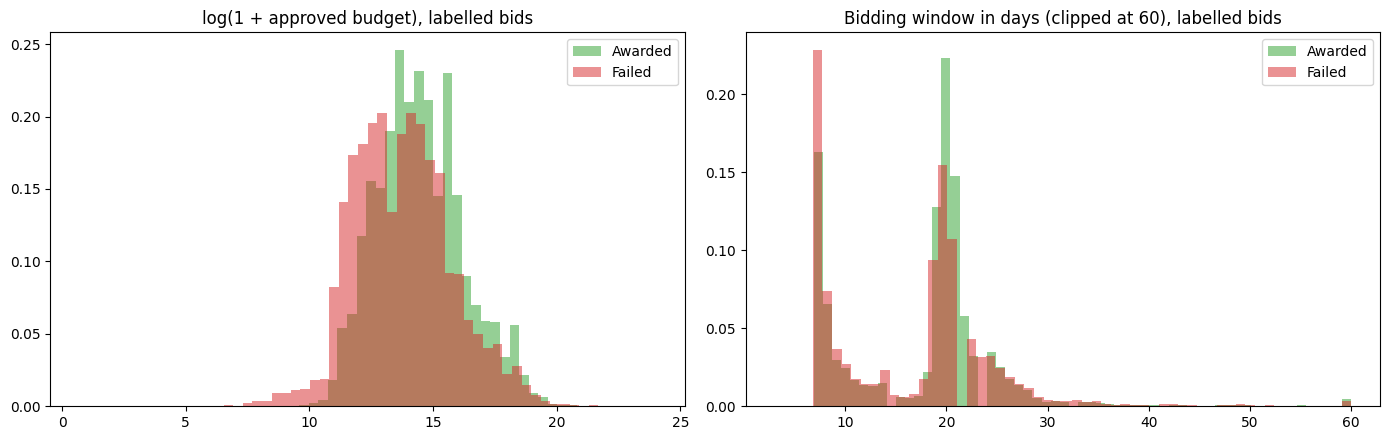

,median approved_budget,median bidding_window_days,median n_line_items
Target_Failed,,,
Awarded,1807851.185,20.0,1.0
Failed,950000.000,19.0,1.0


In [18]:
lab = bids[bids["Target_Failed"].notna()]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for value, name, color in [(0, "Awarded", "tab:green"), (1, "Failed", "tab:red")]:
    s = lab.loc[lab["Target_Failed"] == value]
    axes[0].hist(s["log_approved_budget"], bins=60, alpha=.5, density=True, label=name, color=color)
    axes[1].hist(s["bidding_window_days"].clip(upper=60), bins=60, alpha=.5, density=True, label=name, color=color)
axes[0].set_title("log(1 + approved budget), labelled bids"); axes[0].legend()
axes[1].set_title("Bidding window in days (clipped at 60), labelled bids"); axes[1].legend()
plt.tight_layout(); plt.show()

display(lab.groupby("Target_Failed")[["approved_budget", "bidding_window_days", "n_line_items"]].median()
        .rename(index={0.0: "Awarded", 1.0: "Failed"}).rename(columns=lambda c: f"median {c}"))

### 5.6 Field availability at publication (reviewer Q2)

Every field of the combined dataset is classified by when it becomes known. Only the first group is used as predictors. Award and contract fields are consequences of the outcome and are **excluded**. Identifiers and free text are available at publication but not used in this round.

One caveat cannot be checked from the data. The extracts are final-state snapshots, so a field an agency edited after publication shows its edited value. This is listed as a limitation in notebook 03.

In [19]:
availability = {
    "Available at publication: candidate predictor": [
        "Procuring Entity (PE)", "Region", "Province", "City/Municipality", "Government Branch",
        "PE Organization Type", "PE Organization Type (Grouped)", "Classification", "Procurement Mode",
        "Procurement Mode (Grouped)", "Business Category", "Funding Source", "Funding Instrument",
        "Trade Agreement", "Approved Budget of the Contract", "Published Date", "Closing Date",
        "Area of Delivery", "Contract Duration", "Calendar Type", "Lot Type", "Quantity", "UOM",
        "Item Budget", "UNSPSC Code"],
    "Available at publication: identifier / free text (not used)": [
        "Bid Reference No.", "Solicitation No.", "Notice Title", "Line Item No", "Item Code",
        "Item Name", "Item Description", "UNSPSC Description"],
    "Outcome: defines the target": ["Bid Notice Status"],
    "Known only after bidding: excluded": [
        "Award Reference No.", "Award Title", "Published Date(Award)", "Award Date", "Contract Amount",
        "Award Notice Status", "Notice to Proceed Date", "Contract Effectivity Date", "Contract End Date",
        "Awardee OrgID", "Awardee Organization Name", "Country of Awardee", "Region of Awardee",
        "Province of Awardee", "City/Municipality of Awardee", "Awardee Size", "Awardee Joint Venture"],
    "Lineage (added by the combine script)": ["Source System", "Source File", "Source Quarter"],
}
used_in = {
    "Approved Budget of the Contract": "original 5 + expanded", "Funding Source": "original 5 + expanded",
    "Business Category": "original 5 + expanded", "Region": "original 5 + expanded",
    "Published Date": "original 5 + expanded (month; expanded adds weekday)",
    "Closing Date": "expanded (bidding window)", "Contract Duration": "expanded", "Calendar Type": "expanded",
    "Classification": "expanded", "PE Organization Type (Grouped)": "expanded", "Government Branch": "expanded",
    "Funding Instrument": "expanded", "Trade Agreement": "expanded", "Lot Type": "expanded",
    "Source System": "expanded", "Bid Reference No.": "expanded (number of line items per bid)",
}
table = pd.DataFrame([{"Availability": g, "Field": f, "Used in model": used_in.get(f, "")}
                      for g, fs in availability.items() for f in fs])
assert set(table["Field"]) == set(pfile.schema_arrow.names), set(pfile.schema_arrow.names) ^ set(table["Field"])
display(table)

,Availability,Field,Used in model
0,Available at publication: candidate predictor,Procuring Entity (PE),
1,Available at publication: candidate predictor,Region,original 5 + expanded
2,Available at publication: candidate predictor,Province,
3,Available at publication: candidate predictor,City/Municipality,
4,Available at publication: candidate predictor,Government Branch,expanded
5,Available at publication: candidate predictor,PE Organization Type,
6,Available at publication: candidate predictor,PE Organization Type (Grouped),expanded
7,Available at publication: candidate predictor,Classification,expanded
8,Available at publication: candidate predictor,Procurement Mode,
9,Available at publication: candidate predictor,Procurement Mode (Grouped),


### 5.7 Final modelling table and class balance (reviewer Q4)

The modelling population is the labelled bids, `Target_Failed` ∈ {0, 1}. The full table, including unlabelled bids, is saved so that notebook 03 can study label coverage.

In [20]:
lab = bids[bids["Target_Failed"].notna()]
summary = pd.DataFrame({
    "Bids": [len(bids), len(lab), int((lab.Target_Failed == 0).sum()), int((lab.Target_Failed == 1).sum()), len(bids) - len(lab)],
}, index=["All Public Bidding bids (after quality exclusions)", "Labelled (modelling population)",
          "Awarded (Target_Failed = 0)", "Failed (Target_Failed = 1)", "Unlabelled (excluded)"])
summary["Share of all bids (%)"] = (summary["Bids"] / len(bids) * 100).round(2)
display(summary)
print(f"Failure rate among labelled bids: {lab.Target_Failed.mean() * 100:.2f}% "
      f"(about 1 failed bid for every {(1 - lab.Target_Failed.mean()) / lab.Target_Failed.mean():.1f} awarded)")

by_year = lab.groupby(["published_year", "Source System"], observed=True)["Target_Failed"].agg(
    Labelled="size", Failed="sum", **{"Failure rate (%)": lambda s: round(s.mean() * 100, 2)})
display(by_year)

sens = bids[bids["Target_Failed_or_Cancelled"].notna()]
print(f"\nSensitivity population (Failed or Cancelled vs Awarded): {len(sens):,} bids, "
      f"positive rate {sens.Target_Failed_or_Cancelled.mean() * 100:.2f}%")

bids.to_parquet(pf.BIDS, index=False)
print(f"\nSaved {len(bids):,} bids to {pf.BIDS.relative_to(pf.ROOT)}")

,Bids,Share of all bids (%)
All Public Bidding bids (after quality exclusions),1277213,100.00
Labelled (modelling population),573585,44.91
Awarded (Target_Failed = 0),504350,39.49
Failed (Target_Failed = 1),69235,5.42
Unlabelled (excluded),703628,55.09


Failure rate among labelled bids: 12.07% (about 1 failed bid for every 7.3 awarded)


Labelled   Failed  Failure rate (%)
published_year Source System                                     
2023           1.5              183946  22109.0             12.02
2024           1.5              203625  22261.0             10.93
2025           1.5              105365  12098.0             11.48
2026           1.5               68666   8041.0             11.71
               2.0               11983   4726.0             39.44


Sensitivity population (Failed or Cancelled vs Awarded): 633,767 bids, positive rate 20.42%



Saved 1,277,213 bids to data\processed\bids_public_bidding.parquet


## Summary

- **Sources:** 18 raw files are used: 15 from PhilGEPS 1.5 and 3 from PhilGEPS 2.0. The 12 `2.0_2023`–`2.0_2025` files are verified duplicates of 1.5 files and are skipped.
- **Repairs and harmonisation:** the 2025 Q4 column shift is repaired. Labels that differ only in spelling are harmonised. Vocabularies that genuinely differ are kept, and `Source System` marks them.
- **Unit:** the modelling unit is one bid, keyed by (`Source System`, `Bid Reference No.`).
- **Outcome rule:** `Failed` = 1, `Awarded` = 0. Ongoing, closed, cancelled, shortlisted and conflicting notices are excluded, not counted as failures.
- **Coverage caveat:** label coverage is much lower for recent quarters. Results for those periods are conditional on an outcome having been posted.
- **Outputs:** `data/processed/bids_public_bidding.parquet` (input to notebooks 02 and 03) and `data/processed/bids_public_bidding_exceptions.csv`.